In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Un proyecto se programa con el método de la cadena crítica. Para cada actividad, su responsable ha dado una estimación **segura** (con la que cumpliría aproximadamente nueve de cada diez veces, el percentil 90) y una estimación **agresiva pero alcanzable** (la mediana, el percentil 50), ambas en días. Las actividades no comparten recursos. Los colchones se dimensionan por cortar y pegar, redondeados al día superior.

In [4]:
pregunta_1 = "1. Obtenga el plan de cadena crítica: cadena, colchón del proyecto, colchones de alimentación y fecha comprometida, y la duración del cronograma tradicional (estimaciones seguras).  "
pregunta_2 = "2. Simule 20000 ejecuciones (semilla 9344) en las que las duraciones son independientes y lognormales, con mediana la estimación agresiva y percentil 90 la segura (σ del logaritmo = ln(segura/agresiva)/1,2816; constante si coinciden); las actividades de la cadena empiezan en cuanto terminan sus predecesoras y las de alimentación no antes de su inicio del plan. Calcule la probabilidad de terminar en la duración de la cadena, en la fecha comprometida y en la duración del cronograma tradicional.  "
pregunta_3 = "3. ¿Qué colchón del proyecto haría falta para cumplir con probabilidad 0,90? ¿Y 0,95? Compare con los colchones de cortar y pegar y de la raíz de la suma de cuadrados.  "
pregunta_4 = "4. Simule también la cadena crítica aislada (la suma de las duraciones de sus actividades). ¿Qué probabilidad tendría de cumplir la fecha comprometida? Explique la diferencia con el proyecto completo. ¿Estaba sobreprotegido el cronograma tradicional?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Obtenga el plan de cadena crítica: cadena, colchón del proyecto, colchones de alimentación y fecha comprometida, y la duración del cronograma tradicional (estimaciones seguras).  

2. Simule 20000 ejecuciones (semilla 9344) en las que las duraciones son independientes y lognormales, con mediana la estimación agresiva y percentil 90 la segura (σ del logaritmo = ln(segura/agresiva)/1,2816; constante si coinciden); las actividades de la cadena empiezan en cuanto terminan sus predecesoras y las de alimentación no antes de su inicio del plan. Calcule la probabilidad de terminar en la duración de la cadena, en la fecha comprometida y en la duración del cronograma tradicional.  

3. ¿Qué colchón del proyecto haría falta para cumplir con probabilidad 0,90? ¿Y 0,95? Compare con los colchones de cortar y pegar y de la raíz de la suma de cuadrados.  

4. Simule también la cadena crítica aislada (la suma de las duraciones de sus actividades). ¿Qué probabilidad tendría de cumplir la fecha comprometida? Explique la diferencia con el proyecto completo. ¿Estaba sobreprotegido el cronograma tradicional?  

In [5]:
#| tbl-cap: "Cuadro de datos del enunciado (días)"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, agresiva, segura
    ('A'     , '---'      , 4       , 6     ),
    ('B'     , '---'      , 5       , 8     ),
    ('C'     , '---'      , 3       , 4     ),
    ('D'     , 'B,C'      , 6       , 9     ),
    ('E'     , 'B'        , 6       , 9     ),
    ('F'     , 'C,E'      , 7       , 10    ),
    ('G'     , 'A,F'      , 9       , 12    ),
    ('H'     , 'D,G'      , 4       , 6     ),
], columns=['activity', 'predecessor', 'agresiva', 'segura']).set_index('activity')
datos_enunciado

,predecessor,agresiva,segura
activity,,,
A,---,4,6
B,---,5,8
C,---,3,4
D,"B,C",6,9
E,B,6,9
F,"C,E",7,10
G,"A,F",9,12
H,"D,G",4,6


El proyecto corresponde a la producción de un cortometraje; las actividades son las siguientes (las duraciones del cuadro están en días).

In [6]:
#| tbl-cap: "Descripción de las actividades"
#| label: tbl-descripciones
descripciones = pd.Series({
    'A': 'Guion definitivo',
    'B': 'Casting',
    'C': 'Localizaciones y permisos',
    'D': 'Diseño de vestuario y atrezo',
    'E': 'Plan de rodaje',
    'F': 'Ensayos con los actores',
    'G': 'Rodaje de exteriores',
    'H': 'Rodaje en plató',
}, name='Descripción')
descripciones.to_frame()

,Descripción
A,Guion definitivo
B,Casting
C,Localizaciones y permisos
D,Diseño de vestuario y atrezo
E,Plan de rodaje
F,Ensayos con los actores
G,Rodaje de exteriores
H,Rodaje en plató


# Resolución

In [7]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
datos_proyecto['duration'] = datos_proyecto['agresiva']
RECURSO = None
N, semilla = 20000, 9344

In [8]:
# Funciones auxiliares de la cadena crítica: cálculos intermedios con los números sustituidos
from math import ceil, sqrt
from pmule import grafico_fiebre_tikz
pd.set_option('display.max_colwidth', None)
GANTT_CC = dict(GANTT_PARAMS, period_width=0.6, activity_inner_text_style=r'\bfseries\small')


def sin_decimales(tabla):
    """Números enteros sin «.0» al mostrar una tabla."""
    return tabla.map(lambda v: f'{v:g}' if isinstance(v, float) else v)


def tabla_margenes(datos, actividades):
    """Margen retirado (segura − agresiva) de cada actividad."""
    t = datos.loc[list(actividades), ['segura', 'agresiva']].copy()
    t['margen = segura − agresiva'] = [f'{s} − {a} = {s - a}' for s, a in zip(t['segura'], t['agresiva'])]
    return t.T


def detalle_colchon(margenes, nombre='colchón'):
    """Colchón por cortar y pegar y por la raíz de la suma de cuadrados (redondeo al día superior)."""
    ms = [int(m) for m in margenes]
    suma, cuad = sum(ms), sum(m * m for m in ms)
    cp, rz = 0.5 * suma, sqrt(cuad)
    return pd.DataFrame({nombre: {
        'cortar y pegar = 0,5·Σ márgenes': f"0,5·({' + '.join(map(str, ms))}) = 0,5·{suma} = {cp:g} → {ceil(cp - 1e-9)}",
        'raíz = √(Σ márgenes²)': f"√({' + '.join(f'{m}²' for m in ms)}) = √{cuad} = {rz:.2f} → {ceil(rz - 1e-9)}"}})


def tabla_alimentacion(plan):
    """Colchones de alimentación: arco en el que desemboca la cadena de alimentación, colchón
    requerido, holgura disponible y colchón adoptado."""
    filas = {}
    for nombre, fila in plan.alimentacion.iterrows():
        ms = [int(x) for x in str(fila['margenes']).split(' + ')]
        if plan.metodo_alimentacion == 'cortar_pegar':
            calc = f"0,5·({' + '.join(map(str, ms))}) = {0.5 * sum(ms):g} → {int(fila['requerido'])}"
        else:
            calc = f"√({' + '.join(f'{m}²' for m in ms)}) = {sqrt(sum(m * m for m in ms)):.2f} → {int(fila['requerido'])}"
        entrada = int(plan.inicio_temprano[fila['antes_de']]) if fila['antes_de'] != 'fin' else int(plan.duracion_cadena)
        fin_p = int(plan.inicio_temprano[fila['desde']] + plan.agresiva[fila['desde']])
        filas[nombre] = {'arco': f"{fila['desde']} → {fila['antes_de']}",
                         'cadena de alimentación': fila['cadena_alimentacion'],
                         'colchón requerido': calc,
                         'holgura disponible = inicio de la cadena − fin más temprano': f"{entrada} − {fin_p} = {int(fila['disponible'])}",
                         'colchón adoptado = mín(requerido, disponible)': int(fila['adoptado'])}
    return pd.DataFrame(filas).T


def detalle_alap(plan):
    """Programación lo más tarde posible de las actividades de alimentación (de la última a la primera)."""
    cadena = set(plan.cadena)
    ca = {(fila['desde'], fila['antes_de']): (n, int(fila['adoptado'])) for n, fila in plan.alimentacion.iterrows()}
    suc = {a: sorted(b for b in plan.predecesoras if a in plan.predecesoras[b]) for a in plan.predecesoras}
    filas = {}
    for a in reversed(plan.orden):
        if a in cadena:
            continue
        cands = []
        for b in suc[a]:
            if b in cadena:
                n, fb = ca[(a, b)]
                cands.append(f'{b} − {n}: {int(plan.inicios[b])} − {fb} = {int(plan.inicios[b]) - fb}')
            else:
                cands.append(f'{b}: {int(plan.inicios[b])}')
        if not suc[a]:
            n, fb = ca[(a, 'fin')]
            cands.append(f'fin − {n}: {plan.duracion_cadena} − {fb} = {plan.duracion_cadena - fb}')
        fin = int(plan.inicios[a] + plan.agresiva[a])
        filas[a] = {'fin = mín(inicio de las sucesoras)': f"mín({'; '.join(cands)}) = {fin}",
                    'inicio = fin − duración': f'{fin} − {int(plan.agresiva[a])} = {int(plan.inicios[a])}',
                    'inicio más temprano': int(plan.inicio_temprano[a])}
    return pd.DataFrame(filas).T


def resumen_informes(plan, informes):
    """Cálculos de cada informe de avance con los números sustituidos."""
    T, CP = plan.duracion_cadena, plan.colchon_proyecto
    columnas = {}
    for inf in informes:
        det = inf['detalle']
        curso = det[det['estado'] == 'en curso']
        pend = det[det['estado'] == 'pendiente']
        partes = [f"{r:g} ({a})" for a, r in curso['restante'].items()] + [f"{int(d)} ({a})" for a, d in pend['agresiva'].items()]
        restante = float(det['restante'].sum())
        pa, pc = inf['pct_avance'], inf['pct_consumo']
        columnas[f"día {inf['dia']}"] = {
            'fin previsto = día + restante de la cadena': f"{inf['dia']} + {' + '.join(partes) if partes else '0'} = {inf['fin_previsto']:g}",
            'colchón consumido': f"{inf['fin_previsto']:g} − {T} = {inf['consumo']:g} días → {inf['consumo']:g}/{CP} = {pc:.1f} %",
            'cadena completada': f"({T} − {restante:g})/{T} = {pa:.1f} %",
            'BPI = % colchón restante / % cadena restante': (f"(100 − {pc:.1f})/(100 − {pa:.1f}) = {inf['bpi']:.2f}" if pa < 100 else '—'),
            'límite verde = 10 + 0,6·avance': f"10 + 0,6·{pa:.1f} = {inf['limite_verde']:.1f} %",
            'límite rojo = 30 + 0,6·avance': f"30 + 0,6·{pa:.1f} = {inf['limite_roja']:.1f} %",
            'zona': inf['zona']}
    return pd.DataFrame(columnas)

## Apartado 1

In [9]:
display(Markdown(pregunta_1))

1. Obtenga el plan de cadena crítica: cadena, colchón del proyecto, colchones de alimentación y fecha comprometida, y la duración del cronograma tradicional (estimaciones seguras).  

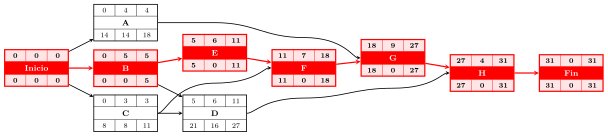

In [10]:
#| fig-cap: "Grafo Roy con las estimaciones agresivas y la cadena crítica"
#| label: fig-pert
proyecto.roy(durations=datos_proyecto['duration'], ranksep=1.2, nodesep=1.2)

Cálculo de los tiempos mínimos y máximos de los nodos del grafo Roy paso a paso (avance con los botones):

In [11]:
proyecto.display_roy_pasos(datos_proyecto['duration'])

In [12]:
plan = proyecto.plan_cadena_critica(datos_proyecto, agresiva='agresiva', segura='segura', recurso=RECURSO)
cadena, T, CP = plan.cadena, plan.duracion_cadena, plan.colchon_proyecto
plan.enlaces_cadena.rename(index=lambda i: i + 1)

,de,a,motivo,recurso
1,B,E,precedencia,
2,E,F,precedencia,
3,F,G,precedencia,
4,G,H,precedencia,


In [13]:
#| tbl-cap: "Colchón del proyecto"
#| label: tbl-colchon
detalle_colchon(plan.margen[cadena], 'colchón del proyecto')

,colchón del proyecto
"cortar y pegar = 0,5·Σ márgenes","0,5·(3 + 3 + 3 + 3 + 2) = 0,5·14 = 7 → 7"
raíz = √(Σ márgenes²),√(3² + 3² + 3² + 3² + 2²) = √40 = 6.32 → 7


In [14]:
#| tbl-cap: "Colchones de alimentación"
#| label: tbl-alimentacion
tabla_alimentacion(plan)

,arco,cadena de alimentación,colchón requerido,holgura disponible = inicio de la cadena − fin más temprano,"colchón adoptado = mín(requerido, disponible)"
CA1,C → F,C,"0,5·(1) = 0.5 → 1",11 − 3 = 8,1
CA2,A → G,A,"0,5·(2) = 1 → 1",18 − 4 = 14,1
CA3,D → H,C - D,"0,5·(1 + 3) = 2 → 2",27 − 11 = 16,2


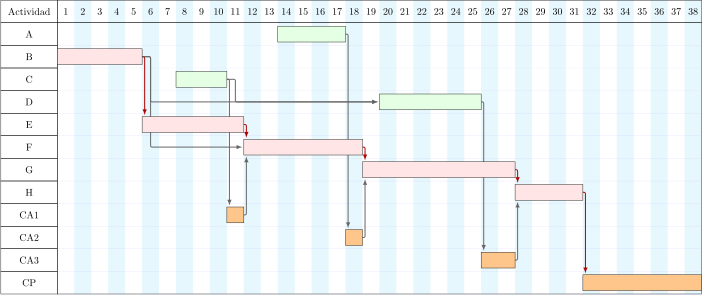

In [15]:
#| fig-cap: "Gantt del plan de cadena crítica"
#| label: fig-ganttCCPM
pinta_tikz(plan.gantt_tikz(params=GANTT_CC))

In [16]:
Markdown(f'Cadena {" - ".join(cadena)} de {T} días; colchón del proyecto {CP}; compromiso **{plan.compromiso} días**. '
         f'Cronograma tradicional (estimaciones seguras): **{plan.duracion_tradicional} días**.')

Cadena B - E - F - G - H de 31 días; colchón del proyecto 7; compromiso **38 días**. Cronograma tradicional (estimaciones seguras): **45 días**.

## Apartado 2

In [17]:
display(Markdown(pregunta_2))

2. Simule 20000 ejecuciones (semilla 9344) en las que las duraciones son independientes y lognormales, con mediana la estimación agresiva y percentil 90 la segura (σ del logaritmo = ln(segura/agresiva)/1,2816; constante si coinciden); las actividades de la cadena empiezan en cuanto terminan sus predecesoras y las de alimentación no antes de su inicio del plan. Calcule la probabilidad de terminar en la duración de la cadena, en la fecha comprometida y en la duración del cronograma tradicional.  

En cada réplica la duración de cada actividad es $a\,e^{\sigma Z}$, con $a$ la estimación agresiva, $Z$ normal tipificada y $\sigma = \ln(s/a)/1{,}2816$, de modo que su mediana es $a$ y su percentil 90 es $s$, la estimación segura. Con ellas se recorre la red (nivelada) hacia delante.

In [18]:
T_sim = plan.simular(N, semilla=semilla, regimen='relevos')
fechas = {'duración de la cadena': T, 'fecha comprometida': plan.compromiso, 'cronograma tradicional': plan.duracion_tradicional}
sin_decimales(pd.DataFrame({'días': fechas, 'P(duración ≤ días)': {k: round(float((T_sim <= v).mean()), 4) for k, v in fechas.items()}}).T)

,duración de la cadena,fecha comprometida,cronograma tradicional
días,31,38,45
P(duración ≤ días),0.242,0.8851,0.9936


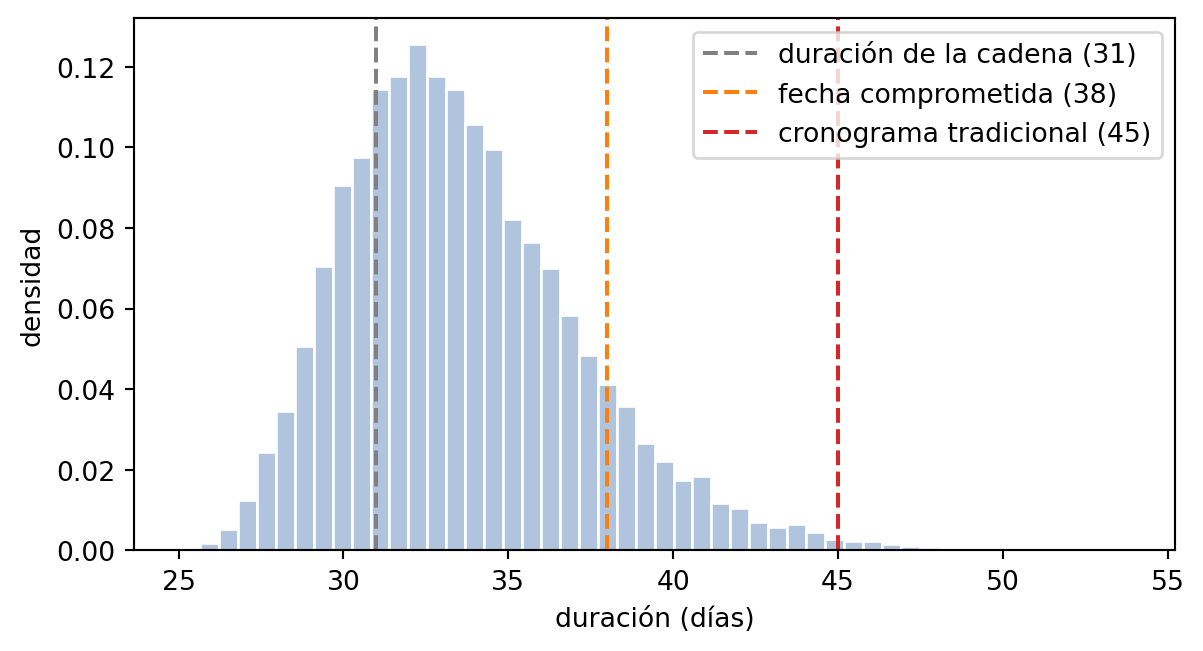

In [19]:
#| fig-cap: "Distribución simulada de la duración del proyecto"
#| label: fig-histograma
from matplotlib import pyplot as plt
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hist(T_sim, bins=50, density=True, color='lightsteelblue', edgecolor='white')
for (nombre, v), color in zip(fechas.items(), ['grey', 'tab:orange', 'tab:red']):
    ax.axvline(v, color=color, linestyle='--', label=f'{nombre} ({v})')
ax.set_xlabel('duración (días)'); ax.set_ylabel('densidad'); ax.legend(); plt.show()

## Apartado 3

In [20]:
display(Markdown(pregunta_3))

3. ¿Qué colchón del proyecto haría falta para cumplir con probabilidad 0,90? ¿Y 0,95? Compare con los colchones de cortar y pegar y de la raíz de la suma de cuadrados.  

In [21]:
#| tbl-cap: "Colchón necesario para cada nivel de confianza"
#| label: tbl-necesario
percentiles = {p: float(np.percentile(T_sim, 100 * p)) for p in (0.5, 0.8, 0.9, 0.95)}
pd.DataFrame({f'P{int(100 * p)}': {'duración': round(v, 2), 'colchón = ⌈percentil − T⌉': f'⌈{v:.2f} − {T}⌉ = {ceil(v - T - 1e-9)}'}
              for p, v in percentiles.items()})

,P50,P80,P90,P95
duración,33.15,36.4,38.39,40.27
colchón = ⌈percentil − T⌉,⌈33.15 − 31⌉ = 3,⌈36.40 − 31⌉ = 6,⌈38.39 − 31⌉ = 8,⌈40.27 − 31⌉ = 10


In [22]:
CP_rz = ceil(plan.calculo_colchon_proyecto['raiz'] - 1e-9)
Markdown(f"Para el 90 % harían falta {ceil(percentiles[0.9] - T - 1e-9)} días de colchón y para el 95 %, {ceil(percentiles[0.95] - T - 1e-9)}. "
         f"Cortar y pegar da {CP} (probabilidad {float((T_sim <= T + CP).mean()):.3f}) y la raíz de la suma de cuadrados {CP_rz} "
         f"(probabilidad {float((T_sim <= T + CP_rz).mean()):.3f}).")

Para el 90 % harían falta 8 días de colchón y para el 95 %, 10. Cortar y pegar da 7 (probabilidad 0.885) y la raíz de la suma de cuadrados 7 (probabilidad 0.885).

## Apartado 4

In [23]:
display(Markdown(pregunta_4))

4. Simule también la cadena crítica aislada (la suma de las duraciones de sus actividades). ¿Qué probabilidad tendría de cumplir la fecha comprometida? Explique la diferencia con el proyecto completo. ¿Estaba sobreprotegido el cronograma tradicional?  

In [24]:
rng = np.random.default_rng(semilla + 1)
a = plan.agresiva[cadena].astype(float).values
s = plan.segura[cadena].astype(float).values
sigma = np.log(s / a) / 1.2816
T_cadena = (a * np.exp(sigma * rng.standard_normal((N, len(cadena))))).sum(axis=1)
pd.DataFrame({'cadena aislada': [float(np.median(T_cadena)), float((T_cadena <= plan.compromiso).mean())],
              'proyecto completo': [float(np.median(T_sim)), float((T_sim <= plan.compromiso).mean())]},
             index=['mediana', 'P(≤ fecha comprometida)']).round(3)

,cadena aislada,proyecto completo
mediana,32.013,33.149
P(≤ fecha comprometida),0.897,0.885


In [25]:
Markdown(f"La cadena aislada cumpliría la fecha comprometida con probabilidad {float((T_cadena <= plan.compromiso).mean()):.3f}; "
         f"el proyecto completo, con {float((T_sim <= plan.compromiso).mean()):.3f}. La diferencia es el **sesgo de convergencia**: "
         "en los puntos donde una cadena de alimentación desemboca en la cadena crítica manda la que llega más tarde, y a veces "
         "el retraso de la alimentación supera su colchón y pasa a la cadena. Los colchones de alimentación existen para que esa "
         "diferencia sea pequeña. "
         f"El cronograma tradicional ({plan.duracion_tradicional} días) se cumpliría con probabilidad {float((T_sim <= plan.duracion_tradicional).mean()):.3f} "
         f"si se ejecutara por relevos: sus {plan.duracion_tradicional - plan.compromiso} días de más sobre el compromiso suben la "
         f"probabilidad de {float((T_sim <= plan.compromiso).mean()):.3f} a {float((T_sim <= plan.duracion_tradicional).mean()):.3f}: "
         "está sobreprotegido, y además, por la ley de Parkinson, esos días tenderían a consumirse igualmente.")

La cadena aislada cumpliría la fecha comprometida con probabilidad 0.897; el proyecto completo, con 0.885. La diferencia es el **sesgo de convergencia**: en los puntos donde una cadena de alimentación desemboca en la cadena crítica manda la que llega más tarde, y a veces el retraso de la alimentación supera su colchón y pasa a la cadena. Los colchones de alimentación existen para que esa diferencia sea pequeña. El cronograma tradicional (45 días) se cumpliría con probabilidad 0.994 si se ejecutara por relevos: sus 7 días de más sobre el compromiso suben la probabilidad de 0.885 a 0.994: está sobreprotegido, y además, por la ley de Parkinson, esos días tenderían a consumirse igualmente.